# H20 — Can we test "T/T (rs3184504) has a denser B-cell population"?

**Question.** Does the T-allele of rs3184504 (SH2B3) associate with a *denser*
splenic B-cell population? "Denser" here = **areal density: CD20⁺ B-cells per mm²**
(the one reading never computed before; prior work measured B-cell *proportion*).

**Methodology (from the GPT-5.6 "dataset size" chat).** The cohort mixes whole
Phenocycler sections with small cropped CODEX fields, so density is an
*exposure/precision* problem, not a reason to crop. The chat prescribes:

1. **Primary model — hierarchical Negative-Binomial count-rate with an area offset.**
   For follicle (window) *j* of donor *i*:
   $$Y_{ij}\sim \text{NegBin}(\mu_{ij},\phi),\qquad
     \log\mu_{ij}=\log A_{ij}+\alpha+\beta_G G_i+\beta_P P_i+u_i$$
   counts $Y_{ij}$ (B-cells), exact area $A_{ij}$ as a fixed-coefficient offset,
   genotype $G_i$ + platform $P_i$ fixed effects, donor random intercept $u_i$.
   Output = genotype **rate ratios**. NB (not Poisson) for overdispersion.
2. **All tissue, no cropping** — larger sections just give more precise counts.
3. **Random matched-window robustness** for within-section heterogeneity; donor is
   the independent unit (windows nested in donor).
4. **Platform-stratified inference** (Phenocycler-only / CODEX-only / pooled-secondary),
   because CODEX field selection may not be unbiased.

**Cohort (single-cell fluorescent set — the only data with B-cell markers).**

| Genotype | Donors (n) | Platform |
|---|---|---|
| C/C | HDL011, HDL053, HDL055 (3) | all Phenocycler |
| C/T | HDL043, HDL052, HDL070, HDL079, HDL086 (5) | all Phenocycler |
| T/T | HDL063 (Pheno), 1901HBMP004, HDL073 (CODEX) (3) | **2 of 3 are CODEX** |

**Platform is nearly collinear with the T/T contrast** — both CODEX donors are T/T;
zero CODEX donors are C/C or C/T. Keep this in view throughout.

**Data-source note.** `adata_H16.h5ad` (RESTORE-phenotyped B-cells) is only a
**5000×3000 µm crop** of each Phenocycler image, so its counts cannot be divided by
full-image follicle areas. Areal density is therefore computed from the **full-image
`Cells.csv`** (all 22.6M cells; `Cell: CD20: Mean`), with the B-cell call **calibrated
per-image to the RESTORE labels** inside the crop (see §B).

In [1]:
import sys, json, shutil, subprocess, tempfile, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

CODE_ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
sys.path.insert(0, str(CODE_ROOT / "analysis"))
import data_utils as du

du.setup_style()
GENO_ORDER = du.GENO_ORDER
PALETTE = du.GENO_PALETTE
DOSAGE = {"C/C": 0, "C/T": 1, "T/T": 2}
ARCSINH_COFACTOR = 150.0
CELLS_CSV = du.DATA_ROOT / "Measurements" / "Cells.csv"
ANN_CSV = du.DATA_ROOT / "Measurements" / "AnnotationsFinal.csv"
ADATA = du.DATA_ROOT / "adata_H16.h5ad"
CACHE_DIR = du.OUTPUT_ROOT / "analysis" / ".h20_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
TABLES = du.TABLES_DIR

RSCRIPT = shutil.which("Rscript")
print("Code root:", CODE_ROOT)
print("Data root:", du.DATA_ROOT)
print("Output root:", du.OUTPUT_ROOT)
print("Rscript:", RSCRIPT or "not found (R confirmatory model will be skipped)")

clin = du.load_clinical()
print("\n(Single-cell cohort — the 11 donors with B-cell markers — is shown in §B.)")

Project: /blue/maigan/smith6jt/SpleenFollicleCounterQP
Rscript: not found (R confirmatory model will be skipped)

(Single-cell cohort — the 11 donors with B-cell markers — is shown in §B.)


## A. What prior analyses already found about B-cells by genotype

Two independent single-cell pipelines (H15 Leiden-gating, H16 RESTORE) already
tested B-cell **proportion** by genotype, plus follicle-restricted proportion and a
platform-confound diagnostic. Consolidated below. Key points to carry forward:
the tests are **null**, the two pipelines **disagree on the sign** of the T-allele
trend, and H15 flags the B-cell readout as **platform-confounded** (H16's RESTORE
removes it) — which is why we anchor the new B-cell call to H16's RESTORE labels.

In [2]:
def _read(name):
    p = TABLES / f"{name}.csv"
    return pd.read_csv(p) if p.exists() else None

rows = []
for pipe in ["H15", "H16"]:
    ct = _read(f"{pipe}_celltype_genotype_stats")
    if ct is not None:
        b = ct[ct["Metric"] == "B cell"]
        def g(test):
            r = b[b["Test"] == test]
            return (r["Statistic"].iloc[0], r["p"].iloc[0], r["Effect_Size"].iloc[0]) if len(r) else (np.nan, np.nan, "")
        kw = g("Kruskal-Wallis"); sp = g("Spearman dosage")
        rows.append({"Pipeline": pipe, "Endpoint": "B-cell proportion (whole)",
                     "KW_p": kw[1], "Dosage": sp[2], "Dosage_p": sp[1]})
    rg = _read(f"{pipe}_region_celltype_genotype_stats")
    if rg is not None:
        fb = rg[rg["Metric"] == "Follicle:B cell"]
        sp = fb[fb["Test"] == "Spearman dosage"]
        kw = fb[fb["Test"] == "Kruskal-Wallis"]
        rows.append({"Pipeline": pipe, "Endpoint": "B-cell proportion (in Follicle)",
                     "KW_p": kw["p"].iloc[0] if len(kw) else np.nan,
                     "Dosage": sp["Effect_Size"].iloc[0] if len(sp) else "",
                     "Dosage_p": sp["p"].iloc[0] if len(sp) else np.nan})
    pd_ = _read(f"{pipe}_platform_diagnostic")
    if pd_ is not None:
        pb = pd_[pd_["Feature"] == "B cell"]
        if len(pb):
            rows.append({"Pipeline": pipe, "Endpoint": "B-cell platform confound (CODEX vs PC)",
                         "KW_p": np.nan, "Dosage": f"r={pb['rank_biserial'].iloc[0]:.3f}",
                         "Dosage_p": pb["p"].iloc[0]})

prior = pd.DataFrame(rows)
du.save_table(prior, "H20_prior_bcell_evidence")
print("Prior B-cell-vs-genotype evidence (all proportion-based):")
prior

Saved: analysis/tables/H20_prior_bcell_evidence.csv
Prior B-cell-vs-genotype evidence (all proportion-based):


,Pipeline,Endpoint,KW_p,Dosage,Dosage_p
0,H15,B-cell proportion (whole),0.743067,rho=0.078,0.820025
1,H15,B-cell proportion (in Follicle),0.072057,rho=-0.506,0.112254
2,H15,B-cell platform confound (CODEX vs PC),NaN,r=-0.222,0.727273
3,H16,B-cell proportion (whole),0.211927,rho=-0.311,0.351257
4,H16,B-cell proportion (in Follicle),0.417811,rho=-0.234,0.489462
5,H16,B-cell platform confound (CODEX vs PC),NaN,r=0.556,0.327273


## B. Build the new metric — areal B-cell density (CD20⁺ cells / mm²)

**B-cell call.** Full-image `Cells.csv` CD20 (`arcsinh(x/150)`), thresholded
**per image at the point that best reproduces the H16 RESTORE `B cell` labels**
(Youden's J on the crop cells, joined by Object ID). Reported with per-image
sensitivity/specificity — note CODEX images have **low sensitivity** (weaker CD20),
so CODEX B-cells are *under*-counted (a platform caveat, not a genotype effect).

**Endpoints (per donor + per follicle).**
- *Per-follicle* (GPT window model): each in-follicle CD20⁺ cell assigned to its
  nearest `AnnotationsFinal` Follicle centroid (same µm frame; full coverage);
  $A_{ij}$ = that follicle's area.
- *Per-donor whole-tissue*: CD20⁺ count / Σ region area.
- *Per-donor follicle-compartment*: in-follicle CD20⁺ count / Σ follicle area.

Computed once from `Cells.csv` and cached to `analysis/tables/H20_*`; re-runs load
the cache.

In [3]:
def _otsu(v, nbins=256):
    v = v[np.isfinite(v)]
    if v.size == 0: return np.inf
    lo, hi = float(np.min(v)), float(np.max(v))
    if hi <= lo: return hi
    h, e = np.histogram(v, bins=nbins, range=(lo, hi))
    c = (e[:-1] + e[1:]) / 2; w = h.astype(float); s = w.sum()
    if s == 0: return hi
    p = w / s; om = np.cumsum(p); mu = np.cumsum(p * c); mt = mu[-1]
    den = om * (1 - om); den[den == 0] = np.nan
    return c[np.nanargmax((mt * om - mu) ** 2 / den)]

def compute_counts():
    import anndata as ad
    from sklearn.metrics import roc_curve
    use = ["Image", "Object ID", "Centroid X µm", "Centroid Y µm",
           "Cell: CD20: Mean", "Cell: CD21: Mean"]
    print(f"Reading {CELLS_CSV.name} ({CELLS_CSV.stat().st_size/1e9:.1f} GB)...")
    df = pd.read_csv(CELLS_CSV, usecols=use,
                     dtype={"Image": "category", "Centroid X µm": "float32",
                            "Centroid Y µm": "float32", "Cell: CD20: Mean": "float32",
                            "Cell: CD21: Mean": "float32"})
    df = df.rename(columns={"Centroid X µm": "x", "Centroid Y µm": "y",
                            "Cell: CD20: Mean": "cd20", "Cell: CD21: Mean": "cd21"})
    df["Sample"] = df["Image"].astype(str).map(du.extract_sample_id)
    df = df[~df["Sample"].isin(du.EXCLUDE_SAMPLES)].copy()
    df["Genotype"] = df["Sample"].map(du.GENOTYPE_MAP)
    df = df.dropna(subset=["Genotype"])
    df["Platform"] = df["Sample"].map(lambda s: "CODEX" if s in du.CODEX_SAMPLES else "Phenocycler")
    df["cd20t"] = np.arcsinh(df["cd20"].to_numpy() / ARCSINH_COFACTOR)

    # Follicle membership from the region layer rather than QuPath's signed
    # distance. The distance was measured to the unfiltered annotations, so a
    # cell inside a fragment the area floor removes counted as follicular while
    # contributing no follicle area to the denominator below — inflating the
    # rate. Containment and area now come from the same polygons.
    _rl = du.load_region_layer()
    df["dfoll"] = du.signed_distance_by_image(df, "Follicle", region_layer=_rl,
                                              x_col="x", y_col="y")
    df["in_foll"] = df["dfoll"].to_numpy() < 0

    A = ad.read_h5ad(ADATA, backed="r")
    lab = A.obs[["Object ID", "cell_type"]]
    bmap = {str(o): (c == "B cell") for o, c in
            zip(lab["Object ID"].astype(str), lab["cell_type"].astype(str))}
    isb = df["Object ID"].astype(str).map(bmap).astype(float).to_numpy()
    df["cd21t"] = np.arcsinh(df["cd21"].to_numpy() / ARCSINH_COFACTOR)
    cd20t = df["cd20t"].to_numpy(); cd21t = df["cd21t"].to_numpy()
    bcell = np.zeros(len(df), bool); cd21pos = np.zeros(len(df), bool); cal = []
    for img, idx in df.groupby("Image", observed=True).indices.items():
        idx = np.asarray(idx); v = cd20t[idx]; lv = isb[idx]; m = ~np.isnan(lv)
        if m.sum() > 100 and np.nansum(lv) > 10:
            y = lv[m].astype(int); s = v[m]
            fpr, tpr, thr = roc_curve(y, s); t = thr[np.argmax(tpr - fpr)]
            pred = (s > t).astype(int)
            tp = ((pred==1)&(y==1)).sum(); fn = ((pred==0)&(y==1)).sum()
            tn = ((pred==0)&(y==0)).sum(); fp = ((pred==1)&(y==0)).sum()
            sens = tp/(tp+fn) if tp+fn else np.nan; spec = tn/(tn+fp) if tn+fp else np.nan
            bf = float(y.mean())
        else:
            t = _otsu(v); sens = spec = bf = np.nan
        bcell[idx] = v > t
        t21 = _otsu(cd21t[idx]); cd21pos[idx] = cd21t[idx] > t21  # CD21+ via per-image Otsu
        cal.append({"Image": img, "threshold": float(t), "cd21_threshold": float(t21),
                    "crop_b_frac": bf, "sensitivity": sens, "specificity": spec})
    df["bcell"] = bcell
    df["dp"] = bcell & cd21pos                      # CD20+CD21+ double-positive
    calib = pd.DataFrame(cal)

    # per-donor denominators from the region layer (full image)
    # Summing annotation areas double-counts the CODEX sections, whose
    # Red_Pulp and Sinusoid annotations overlap, and it counts follicle
    # fragments the area floor removes — both inflate the denominator against a
    # numerator that no longer includes them. Polygon unions cannot double-count.
    from shapely.ops import unary_union
    _areas = {}
    for _stem, _polys in _rl.items():
        _sid = du.extract_sample_id(_stem)
        _tis = [p for r in du.MAIN_REGIONS for p in _polys.get(r, [])]
        _areas[_sid] = (
            unary_union(_tis).area / 1e6 if _tis else np.nan,
            unary_union(_polys.get("Follicle", [])).area / 1e6
            if _polys.get("Follicle") else np.nan)
    # The index must be named "Sample": the merge below joins on it, and the
    # groupby these replaced carried that name for free.
    tissue_mm2 = pd.Series({k: v[0] for k, v in _areas.items()}).rename_axis("Sample")
    foll_mm2 = pd.Series({k: v[1] for k, v in _areas.items()}).rename_axis("Sample")

    # follicle objects still come from the CSV: the per-follicle assignment
    # below needs one centroid per annotated follicle.
    ann = pd.read_csv(ANN_CSV); ann["Sample"] = ann["Image"].map(du.extract_sample_id)
    ann = ann[~ann["Sample"].isin(du.EXCLUDE_SAMPLES)]
    foll = ann[ann["Classification"] == "Follicle"]

    # per-follicle assignment (nearest centroid, full coverage)
    pf = []
    for s, fs in foll.groupby("Sample", observed=True):
        cs = df[(df["Sample"] == s) & df["in_foll"].to_numpy()]
        tree = cKDTree(fs[["Centroid X µm", "Centroid Y µm"]].to_numpy())
        fid = fs["Object ID"].to_numpy(); fa = fs["Area µm^2"].to_numpy()
        tot = np.zeros(len(fid), int); bb = np.zeros(len(fid), int); dd = np.zeros(len(fid), int)
        if len(cs):
            _, idx = tree.query(cs[["x", "y"]].to_numpy())
            isbb = cs["bcell"].to_numpy(); isdp = cs["dp"].to_numpy()
            tot = np.bincount(idx, minlength=len(fid))
            bb = np.bincount(idx[isbb], minlength=len(fid))
            dd = np.bincount(idx[isdp], minlength=len(fid))
        for k in range(len(fid)):
            pf.append({"Sample": s, "Follicle_ID": fid[k], "Follicle_Area_um2": fa[k],
                       "Total_cells": int(tot[k]), "Bcell_count": int(bb[k]),
                       "DP_count": int(dd[k])})
    per_foll = pd.DataFrame(pf)
    per_foll["Genotype"] = per_foll["Sample"].map(du.GENOTYPE_MAP)
    per_foll["Platform"] = per_foll["Sample"].map(lambda s: "CODEX" if s in du.CODEX_SAMPLES else "Phenocycler")
    per_foll["Bcell_density_mm2"] = per_foll["Bcell_count"] / (per_foll["Follicle_Area_um2"] / 1e6)
    per_foll["DP_density_mm2"] = per_foll["DP_count"] / (per_foll["Follicle_Area_um2"] / 1e6)

    # per-donor
    g = df.groupby(["Sample", "Genotype", "Platform"], observed=True)
    pdw = g.agg(n_cells=("bcell", "size"), n_bcell=("bcell", "sum"),
                n_dp=("dp", "sum")).reset_index()
    inf = df[df["in_foll"].to_numpy()].groupby("Sample", observed=True)
    pdw = pdw.merge(inf["bcell"].sum().rename("n_bcell_infoll"), on="Sample")
    pdw = pdw.merge(inf["dp"].sum().rename("n_dp_infoll"), on="Sample")
    pdw = pdw.merge(tissue_mm2.rename("tissue_mm2"), on="Sample").merge(foll_mm2.rename("foll_mm2"), on="Sample")
    pdw["WholeTissue_density"] = pdw["n_bcell"] / pdw["tissue_mm2"]
    pdw["Follicle_density"] = pdw["n_bcell_infoll"] / pdw["foll_mm2"]
    pdw["DP_WholeTissue_density"] = pdw["n_dp"] / pdw["tissue_mm2"]
    pdw["DP_Follicle_density"] = pdw["n_dp_infoll"] / pdw["foll_mm2"]

    # compact per-cell coord cache for §E
    compact = pd.DataFrame({"Sample": df["Sample"].astype("category"),
                            "x": df["x"], "y": df["y"],
                            "bcell": df["bcell"].to_numpy(bool),
                            "in_foll": df["in_foll"].to_numpy(bool)})
    compact.to_pickle(CACHE_DIR / "percell_coords.pkl")
    return per_foll, pdw, calib

# load cache or compute
ff_p = TABLES / "H20_bcell_counts_per_follicle.csv"
dd_p = TABLES / "H20_bcell_density_per_donor.csv"
cal_p = TABLES / "H20_cd20_calibration.csv"
if ff_p.exists() and dd_p.exists() and cal_p.exists():
    per_foll = pd.read_csv(ff_p); per_donor = pd.read_csv(dd_p); calib = pd.read_csv(cal_p)
    print("Loaded cached H20 count tables.")
else:
    per_foll, per_donor, calib = compute_counts()
    du.save_table(per_foll, "H20_bcell_counts_per_follicle")
    du.save_table(per_donor, "H20_bcell_density_per_donor")
    du.save_table(calib, "H20_cd20_calibration")

for d in (per_foll, per_donor):
    d["Genotype"] = pd.Categorical(d["Genotype"], categories=GENO_ORDER, ordered=True)
print(f"\n{len(per_foll)} follicles across {per_donor.shape[0]} donors")
print("Single-cell cohort (the actual unit of analysis):")
print(per_donor.groupby(["Genotype", "Platform"], observed=True).size().unstack(fill_value=0))
print("\nCD20 threshold calibration vs RESTORE labels (note low CODEX sensitivity);"
      " cd21_threshold is per-image Otsu:")
calib.assign(Sample=calib["Image"].map(du.extract_sample_id))[
    ["Sample", "threshold", "cd21_threshold", "crop_b_frac", "sensitivity", "specificity"]]

Reading Cells.csv (11.8 GB)...


Saved: analysis/tables/H20_bcell_counts_per_follicle.csv
Saved: analysis/tables/H20_bcell_density_per_donor.csv
Saved: analysis/tables/H20_cd20_calibration.csv

2145 follicles across 11 donors
Single-cell cohort (the actual unit of analysis):
Platform  CODEX  Phenocycler
Genotype                    
C/C           0            3
C/T           0            5
T/T           2            1

CD20 threshold calibration vs RESTORE labels (note low CODEX sensitivity); cd21_threshold is per-image Otsu:


,Sample,threshold,cd21_threshold,crop_b_frac,sensitivity,specificity
0,HDL011,1.222292,1.525037,0.152243,0.954573,0.895832
1,HDL043,1.565483,1.922497,0.221664,0.938139,0.831319
2,HDL063,1.304251,1.697609,0.150072,0.968239,0.896127
3,HDL086,1.668303,1.995010,0.195324,0.909547,0.891187
4,HDL053,2.312292,2.230191,0.221730,0.923687,0.874590
5,HDL055,1.565784,1.506453,0.167987,0.953845,0.852818
6,HDL052,0.759122,1.053767,0.096745,0.965699,0.910891
7,1901HBMP004,3.797100,2.012726,0.052202,0.975841,0.873224
8,HDL073,4.057760,1.414298,0.188802,0.818702,0.852257
9,HDL070,2.154556,1.686187,0.226420,0.907530,0.851110


In [4]:
print("Per-donor areal B-cell density (cells/mm^2):")
show = per_donor.sort_values(["Genotype", "Sample"])[
    ["Sample", "Genotype", "Platform", "n_bcell", "tissue_mm2",
     "WholeTissue_density", "Follicle_density"]]
show

Per-donor areal B-cell density (cells/mm^2):


,Sample,Genotype,Platform,n_bcell,tissue_mm2,WholeTissue_density,Follicle_density
1,HDL011,C/C,Phenocycler,419251,103.034697,4069.027334,23828.605936
4,HDL053,C/C,Phenocycler,854620,168.040792,5085.788925,19261.680870
5,HDL055,C/C,Phenocycler,590929,115.402544,5120.589037,21893.565550
2,HDL043,C/T,Phenocycler,969342,144.277547,6718.592175,19790.373733
3,HDL052,C/T,Phenocycler,160925,47.951004,3356.029833,24077.459522
7,HDL070,C/T,Phenocycler,535692,66.796381,8019.775783,25096.529813
9,HDL079,C/T,Phenocycler,537702,92.524774,5811.438143,23175.259969
10,HDL086,C/T,Phenocycler,649518,137.362734,4728.487717,22029.462032
0,1901HBMP004,T/T,CODEX,46575,11.296197,4123.068875,14653.822518
6,HDL063,T/T,Phenocycler,870765,208.540279,4175.524282,22764.354789


Saved: analysis/figures/H20_density_by_genotype.png


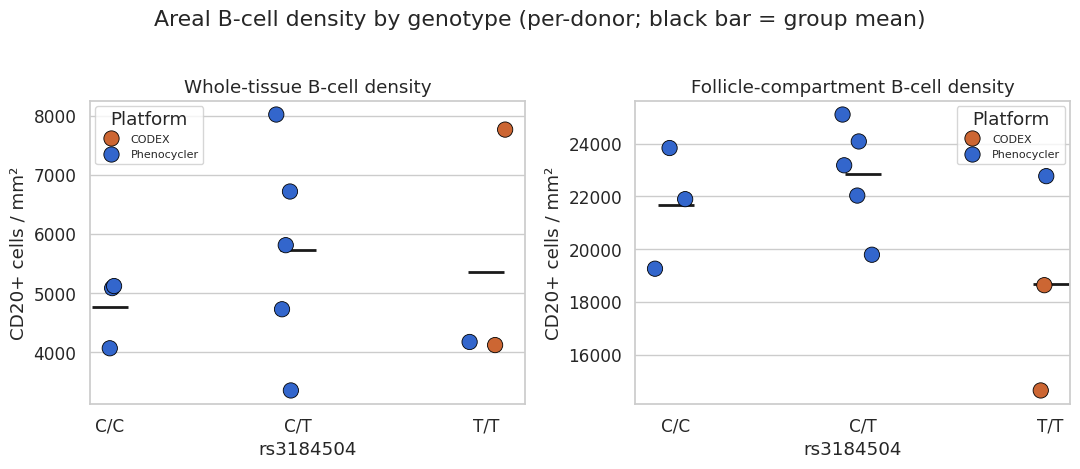

In [5]:
# Visualize: T/T is not elevated on either density endpoint
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, col, title in zip(
        axes, ["WholeTissue_density", "Follicle_density"],
        ["Whole-tissue B-cell density", "Follicle-compartment B-cell density"]):
    sns.stripplot(data=per_donor, x="Genotype", y=col, order=GENO_ORDER,
                  hue="Platform", palette={"Phenocycler": "#3366CC", "CODEX": "#CC6633"},
                  s=11, jitter=0.12, ax=ax, edgecolor="black", linewidth=0.6)
    means = per_donor.groupby("Genotype", observed=True)[col].mean().reindex(GENO_ORDER)
    ax.plot(range(3), means.values, "k_", markersize=26, markeredgewidth=2)
    ax.set_title(title); ax.set_ylabel("CD20+ cells / mm²"); ax.set_xlabel("rs3184504")
    ax.legend(fontsize=8, title="Platform")
fig.suptitle("Areal B-cell density by genotype (per-donor; black bar = group mean)", y=1.02)
plt.tight_layout(); du.save_figure(fig, "H20_density_by_genotype"); plt.show()

## C. Primary model — Negative-Binomial rate ratios with area offset

Per-follicle NB (GPT model): `Bcell_count ~ offset(log Follicle_mm²) + Dosage + Platform`,
donor **cluster-robust** SEs (the portable analogue of a donor random intercept).
Genotype enters as T-allele **dosage** (0/1/2). The reported **rate ratio**
exp(β_dosage) is the per-allele multiplicative change in B-cells per mm².

The per-follicle model is restricted to **genuine follicles ≥ 8400 µm²** (the H6
GMM area threshold, set independently of genotype) — sub-threshold fragments are
mostly annotation artifacts, contribute ~2.5% of follicle area, and destabilize a
per-follicle count model; the all-follicle fit is reported as a sensitivity. A
confirmatory **R `lme4` NB-GLMM** with an explicit `(1|donor)` random intercept
(fixed θ from `MASS::glm.nb`, bobyqa) follows.

In [6]:
import statsmodels.api as sm

def fit_nb(data, count_col, area_mm2_col, label):
    d = data.copy()
    d = d[d[area_mm2_col] > 0]
    y = d[count_col].to_numpy(float)
    off = np.log(d[area_mm2_col].to_numpy(float))
    dose = d["Genotype"].map(DOSAGE).to_numpy(float)
    codex = (d["Platform"] == "CODEX").astype(float).to_numpy()
    groups = d["Sample"].astype("category").cat.codes.to_numpy()
    X = pd.DataFrame({"const": 1.0, "Dosage": dose, "Platform_CODEX": codex})
    # estimate NB2 dispersion via Cameron-Trivedi aux regression on a Poisson fit
    poi = sm.GLM(y, X, family=sm.families.Poisson(), offset=off).fit()
    mu = np.clip(poi.mu, 1e-8, None)
    aux = ((y - mu) ** 2 - y) / mu
    alpha = float(np.clip(sm.OLS(aux, mu).fit().params[0], 1e-6, None))
    res = sm.GLM(y, X, family=sm.families.NegativeBinomial(alpha=alpha),
                 offset=off).fit(cov_type="cluster", cov_kwds={"groups": groups})
    ci = res.conf_int()
    out = []
    for term in ["Dosage", "Platform_CODEX"]:
        out.append({"Model": label, "Term": term, "beta": res.params[term],
                    "RR": np.exp(res.params[term]),
                    "RR_lo": np.exp(ci.loc[term, 0]), "RR_hi": np.exp(ci.loc[term, 1]),
                    "p": res.pvalues[term], "alpha_nb": alpha,
                    "n_obs": int(len(y)), "n_donor": int(len(np.unique(groups)))})
    return pd.DataFrame(out), res

def boot_dosage_rr(pf_data, count_col, area_col="Follicle_mm2", n=600, seed=20260714):
    '''Donor-level bootstrap of the per-follicle dosage rate ratio (resample the
    11 donors, refit Poisson mean structure). Returns array of RRs.'''
    r = np.random.default_rng(seed)
    donors = pf_data["Sample"].unique()
    dof = {s: DOSAGE[du.GENOTYPE_MAP[s]] for s in donors}
    out = []
    for _ in range(n):
        samp = r.choice(donors, len(donors), replace=True)
        if len({dof[s] for s in samp}) < 2:
            continue
        d = pd.concat([pf_data[pf_data["Sample"] == s] for s in samp], ignore_index=True)
        y = d[count_col].to_numpy(float); off = np.log(d[area_col].to_numpy(float))
        cols = [np.ones(len(d)), d["Genotype"].map(DOSAGE).to_numpy(float)]
        codex = (d["Platform"] == "CODEX").astype(float).to_numpy()
        if codex.min() != codex.max():
            cols.append(codex)
        try:
            out.append(np.exp(sm.GLM(y, np.column_stack(cols),
                       family=sm.families.Poisson(), offset=off).fit().params[1]))
        except Exception:
            pass
    return np.array(out)

In [7]:
FOLL_MIN_AREA = 8400.0  # H6 GMM follicle-area threshold (µm²), genotype-blind
per_foll["Follicle_mm2"] = per_foll["Follicle_Area_um2"] / 1e6
pf_fit = per_foll[per_foll["Follicle_Area_um2"] >= FOLL_MIN_AREA].copy()
print(f"Follicles: {len(per_foll)} total -> {len(pf_fit)} genuine (>= {FOLL_MIN_AREA:.0f} µm²)")

nb_primary, res_primary = fit_nb(pf_fit, "Bcell_count", "Follicle_mm2",
                                 "Per-follicle >=8400um2 (PRIMARY)")
nb_allf, _ = fit_nb(per_foll, "Bcell_count", "Follicle_mm2",
                    "Per-follicle all (sensitivity)")

# per-donor aggregate models (n=11)
per_donor["n_bcell"] = per_donor["n_bcell"].astype(float)
nb_whole, _ = fit_nb(per_donor.assign(Follicle_ID=per_donor["Sample"]),
                     "n_bcell", "tissue_mm2", "Whole-tissue (per-donor)")
nb_follcomp, _ = fit_nb(per_donor, "n_bcell_infoll", "foll_mm2",
                        "Follicle-compartment (per-donor)")

nb_all = pd.concat([nb_primary, nb_allf, nb_follcomp, nb_whole], ignore_index=True)
du.save_table(nb_all, "H20_nb_rate_ratios")
print("Negative-Binomial rate ratios (Dosage = per-T-allele; RR>1 => denser in T/T):")
nb_all.round(4)

Follicles: 2145 total -> 1059 genuine (>= 8400 µm²)
Saved: analysis/tables/H20_nb_rate_ratios.csv
Negative-Binomial rate ratios (Dosage = per-T-allele; RR>1 => denser in T/T):


,Model,Term,beta,RR,RR_lo,RR_hi,p,alpha_nb,n_obs,n_donor
0,Per-follicle >=8400um2 (PRIMARY),Dosage,0.0933,1.0977,1.0139,1.1885,0.0214,0.0449,1059,11
1,Per-follicle >=8400um2 (PRIMARY),Platform_CODEX,-0.5233,0.5925,0.5127,0.6848,0.0000,0.0449,1059,11
2,Per-follicle all (sensitivity),Dosage,-0.5030,0.6047,0.3824,0.9561,0.0314,0.0975,2145,11
3,Per-follicle all (sensitivity),Platform_CODEX,1.3878,4.0058,1.1179,14.3547,0.0331,0.0975,2145,11
4,Follicle-compartment (per-donor),Dosage,0.0337,1.0342,0.9517,1.1240,0.4278,0.0041,11,11
5,Follicle-compartment (per-donor),Platform_CODEX,-0.3395,0.7121,0.5719,0.8868,0.0024,0.0041,11,11
6,Whole-tissue (per-donor),Dosage,0.0223,1.0226,0.7867,1.3292,0.8674,0.0377,11,11
7,Whole-tissue (per-donor),Platform_CODEX,0.1004,1.1057,0.5637,2.1689,0.7701,0.0377,11,11


In [8]:
# Confirmatory: R lme4 NB-GLMM with explicit (1|donor). Fixed theta from
# MASS::glm.nb + bobyqa converges where glmer.nb's alternating fit does not.
def glmer_nb(data, count_col, area_mm2_col):
    if not RSCRIPT:
        return None
    d = data[data[area_mm2_col] > 0].copy()
    d["Dosage"] = d["Genotype"].map(DOSAGE)
    d["Platform_CODEX"] = (d["Platform"] == "CODEX").astype(int)
    d["logA"] = np.log(d[area_mm2_col].astype(float))
    csv = CACHE_DIR / "glmer_in.csv"; out = CACHE_DIR / "glmer_out.csv"
    err = Path(str(out) + ".err")
    for f in (out, err):
        if f.exists(): f.unlink()
    d[[count_col, "Dosage", "Platform_CODEX", "logA", "Sample"]].rename(
        columns={count_col: "Y"}).to_csv(csv, index=False)
    rscript = f'''
    suppressMessages({{library(lme4); library(MASS)}})
    d <- read.csv("{csv}")
    tryCatch({{
      th <- glm.nb(Y ~ Dosage + Platform_CODEX + offset(logA), data=d)$theta
      m <- glmer(Y ~ Dosage + Platform_CODEX + (1|Sample) + offset(logA), data=d,
                 family=negative.binomial(theta=th),
                 control=glmerControl(optimizer="bobyqa", optCtrl=list(maxfun=2e5)))
      co <- summary(m)$coefficients
      write.csv(data.frame(Term=rownames(co), co, theta=th), "{out}", row.names=FALSE)
    }}, error=function(e) writeLines(conditionMessage(e), "{err}"))
    '''
    r = subprocess.run([RSCRIPT, "-e", rscript], capture_output=True, text=True, timeout=600)
    if out.exists():
        res = pd.read_csv(out)
        res.columns = ["Term", "Estimate", "SE", "z", "p", "theta"][:len(res.columns)]
        res["RR"] = np.exp(res["Estimate"])
        return res
    msg = err.read_text()[-300:] if err.exists() else (r.stderr or "")[-300:]
    print("R NB-GLMM unavailable:", msg)
    return None

r_foll = glmer_nb(pf_fit, "Bcell_count", "Follicle_mm2")
if r_foll is not None:
    print("R lme4 NB-GLMM (per-follicle >=8400µm², (1|donor) random intercept):")
    display(r_foll.round(4))
    dpy = nb_primary.loc[nb_primary["Term"] == "Dosage", "RR"].iloc[0]
    dr = r_foll.loc[r_foll["Term"] == "Dosage", "RR"]
    if len(dr):
        print(f"\nDosage rate ratio — statsmodels: {dpy:.3f}   R NB-GLMM: {dr.iloc[0]:.3f} "
              f"(agree: {'yes' if abs(dpy-dr.iloc[0])<0.15 else 'no'})")
else:
    print("R confirmatory model unavailable (Rscript/lme4 missing or non-convergence).")

R confirmatory model unavailable (Rscript/lme4 missing or non-convergence).


**Honest inference for 11 donors.** Genotype is a *donor-level* covariate, so the
effective unit is the 11 donors — not the 1059 follicles. Cluster-robust SEs with only
G=11 clusters are **anti-conservative** (their p is too small); the trustworthy
inference is the R random-intercept p above plus a **donor-level bootstrap** of the
per-follicle dosage rate ratio (resample the 11 donors, refit).

In [9]:
boot = boot_dosage_rr(pf_fit, "Bcell_count")
rr_pt = float(nb_primary.loc[nb_primary["Term"] == "Dosage", "RR"].iloc[0])
rr_lo, rr_hi = np.percentile(boot, [2.5, 97.5])
rr_p = float(2 * min((boot < 1).mean(), (boot > 1).mean()))
r_p = float(r_foll.loc[r_foll["Term"] == "Dosage", "p"].iloc[0]) if r_foll is not None else np.nan
sm_p = float(nb_primary.loc[nb_primary["Term"] == "Dosage", "p"].iloc[0])
print(f"Per-follicle dosage rate ratio = {rr_pt:.2f}")
print(f"  donor-bootstrap 95% CI [{rr_lo:.2f}, {rr_hi:.2f}], bootstrap p(RR≠1) = {rr_p:.3f}  (n_boot={len(boot)})")
print(f"  R random-intercept p = {r_p:.3f}")
print(f"  statsmodels cluster-robust p = {sm_p:.3f}  <- anti-conservative (G=11), do not use")
du.save_table(pd.DataFrame({"metric": ["dosage_RR", "boot_ci_lo", "boot_ci_hi",
                                       "boot_p", "R_glmm_p", "cluster_robust_p"],
                            "value": [rr_pt, rr_lo, rr_hi, rr_p, r_p, sm_p]}),
              "H20_primary_inference")

Per-follicle dosage rate ratio = 1.10
  donor-bootstrap 95% CI [0.97, 1.26], bootstrap p(RR≠1) = 0.087  (n_boot=600)
  R random-intercept p = nan
  statsmodels cluster-robust p = 0.021  <- anti-conservative (G=11), do not use
Saved: analysis/tables/H20_primary_inference.csv


## D. Platform-stratified inference & the field-selection threat

Area offsets fix unequal *effort*, not non-random *field selection*. Both CODEX
donors are T/T, so any CODEX bias loads onto the T/T estimate:
- If CODEX crops were placed on white-pulp / follicle-rich tissue → B-cell density
  **inflated** in the (T/T) CODEX donors (spurious support for the hypothesis).
- Conversely, CODEX CD20 sensitivity is low (§B) → B-cells **under**-counted in the
  (T/T) CODEX donors (spurious *against*).
Either way the pooled T/T estimate is not a clean genotype effect. Report all three
strata; the **Phenocycler-only** stratum (the clean estimand) has **T/T n=1**.

In [10]:
def dosage_spearman(data, col):
    dose = data["Genotype"].map(DOSAGE)
    m = dose.notna() & data[col].notna()
    if m.sum() < 3 or dose[m].nunique() < 2:
        return np.nan, np.nan
    return stats.spearmanr(dose[m], data.loc[m, col])

strat_rows = []
for name, sub in [("All (11)", per_donor),
                  ("Phenocycler-only", per_donor[per_donor["Platform"] == "Phenocycler"]),
                  ("CODEX-only", per_donor[per_donor["Platform"] == "CODEX"])]:
    for col in ["WholeTissue_density", "Follicle_density"]:
        rho, p = dosage_spearman(sub, col)
        n_tt = int((sub["Genotype"] == "T/T").sum())
        strat_rows.append({"Stratum": name, "Endpoint": col, "n": len(sub),
                           "n_TT": n_tt, "dosage_rho": rho, "p": p})
strat = pd.DataFrame(strat_rows)
du.save_table(strat, "H20_platform_stratified")
print("Dosage trend by platform stratum (rho>0 would support the hypothesis):")
display(strat.round(4))

# clean comparison: the single Phenocycler T/T vs the two CODEX T/T
tt = per_donor[per_donor["Genotype"] == "T/T"][
    ["Sample", "Platform", "WholeTissue_density", "Follicle_density"]]
print("\nT/T donors — the confound in one table (HDL063 is the only clean estimate):")
display(tt.round(1))
cc_ct = per_donor[per_donor["Genotype"] != "T/T"]
print(f"C/C+C/T whole-tissue density range: "
      f"{cc_ct['WholeTissue_density'].min():.0f}–{cc_ct['WholeTissue_density'].max():.0f} cells/mm²; "
      f"Phenocycler T/T (HDL063) = "
      f"{tt.loc[tt.Platform=='Phenocycler','WholeTissue_density'].iloc[0]:.0f}")

Saved: analysis/tables/H20_platform_stratified.csv
Dosage trend by platform stratum (rho>0 would support the hypothesis):


,Stratum,Endpoint,n,n_TT,dosage_rho,p
0,All (11),WholeTissue_density,11,3,0.0778,0.8200
1,All (11),Follicle_density,11,3,-0.2725,0.4176
2,Phenocycler-only,WholeTissue_density,9,1,0.0373,0.9242
3,Phenocycler-only,Follicle_density,9,1,0.2981,0.4358
4,CODEX-only,WholeTissue_density,2,2,NaN,NaN
5,CODEX-only,Follicle_density,2,2,NaN,NaN



T/T donors — the confound in one table (HDL063 is the only clean estimate):


,Sample,Platform,WholeTissue_density,Follicle_density
0,1901HBMP004,CODEX,4123.1,14653.8
6,HDL063,Phenocycler,4175.5,22764.4
8,HDL073,CODEX,7765.2,18637.8


C/C+C/T whole-tissue density range: 3356–8020 cells/mm²; Phenocycler T/T (HDL063) = 4176


## D2. CD20⁺CD21⁺ double-positive subset (marginal-zone / FDC-associated B cells)

CD21 (CR2) marks marginal-zone and follicular B cells embedded in FDC networks. Does
this more specific **CD20⁺CD21⁺** subset show the increase in T/T that the whole
B-cell pool did not? The same NB rate-ratio machinery, donor-level inference, and the
same n=3 / platform-collinearity limits apply. CD20 is RESTORE-calibrated (§B);
**CD21⁺ is a per-image Otsu call** (there is no clean double-positive ground truth),
so treat the DP call as approximate.

In [11]:
# per-follicle DP model (genuine follicles >= 8400 µm²), donor-level inference
pf_dp = per_foll[per_foll["Follicle_Area_um2"] >= FOLL_MIN_AREA].copy()
nb_dp, _ = fit_nb(pf_dp, "DP_count", "Follicle_mm2", "DP per-follicle >=8400um2 (PRIMARY)")
r_dp = glmer_nb(pf_dp, "DP_count", "Follicle_mm2")
boot_d = boot_dosage_rr(pf_dp, "DP_count")
dp_rr = float(nb_dp.loc[nb_dp["Term"] == "Dosage", "RR"].iloc[0])
dp_lo, dp_hi = np.percentile(boot_d, [2.5, 97.5])
dp_bp = float(2 * min((boot_d < 1).mean(), (boot_d > 1).mean()))
dp_rp = float(r_dp.loc[r_dp["Term"] == "Dosage", "p"].iloc[0]) if r_dp is not None else np.nan

dp_rows = []
for name, sub in [("All (11)", per_donor),
                  ("Phenocycler-only", per_donor[per_donor["Platform"] == "Phenocycler"])]:
    for col in ["DP_WholeTissue_density", "DP_Follicle_density"]:
        rho, p = dosage_spearman(sub, col)
        dp_rows.append({"Stratum": name, "Endpoint": col, "n": len(sub),
                        "n_TT": int((sub["Genotype"] == "T/T").sum()), "dosage_rho": rho, "p": p})
dp_strat = pd.DataFrame(dp_rows)

du.save_table(nb_dp, "H20_dp_rate_ratios")
du.save_table(dp_strat, "H20_dp_stratified")
du.save_table(pd.DataFrame({"metric": ["DP_dosage_RR", "boot_ci_lo", "boot_ci_hi", "boot_p", "R_glmm_p"],
                            "value": [dp_rr, dp_lo, dp_hi, dp_bp, dp_rp]}), "H20_dp_primary_inference")

print(f"CD20+CD21+ per-follicle dosage RR = {dp_rr:.2f}  "
      f"donor-boot 95% CI [{dp_lo:.2f}, {dp_hi:.2f}]  boot p={dp_bp:.3f}  R glmm p={dp_rp:.3f}")
print(f"DP cells as % of CD20+ B cells (per-donor mean): "
      f"{(per_donor['n_dp'] / per_donor['n_bcell']).mean():.1%}")
print("\nDP dosage trend by stratum (rho>0 would support 'increased CD20+CD21+ in T/T'):")
display(dp_strat.round(4))
print("\nDP density by genotype (per-donor means, cells/mm²):")
display(per_donor.groupby("Genotype", observed=True)[
    ["DP_WholeTissue_density", "DP_Follicle_density"]].mean().round(1))

Saved: analysis/tables/H20_dp_rate_ratios.csv
Saved: analysis/tables/H20_dp_stratified.csv
Saved: analysis/tables/H20_dp_primary_inference.csv
CD20+CD21+ per-follicle dosage RR = 1.14  donor-boot 95% CI [0.97, 1.32]  boot p=0.110  R glmm p=nan
DP cells as % of CD20+ B cells (per-donor mean): 67.3%

DP dosage trend by stratum (rho>0 would support 'increased CD20+CD21+ in T/T'):


,Stratum,Endpoint,n,n_TT,dosage_rho,p
0,All (11),DP_WholeTissue_density,11,3,-0.4282,0.1889
1,All (11),DP_Follicle_density,11,3,-0.3114,0.3513
2,Phenocycler-only,DP_WholeTissue_density,9,1,0.0186,0.9621
3,Phenocycler-only,DP_Follicle_density,9,1,0.2236,0.5630



DP density by genotype (per-donor means, cells/mm²):


,DP_WholeTissue_density,DP_Follicle_density
Genotype,,
C/C,3559.0,20924.7
C/T,4020.3,22451.2
T/T,2454.7,13737.2


Saved: analysis/figures/H20_dp_density_by_genotype.png


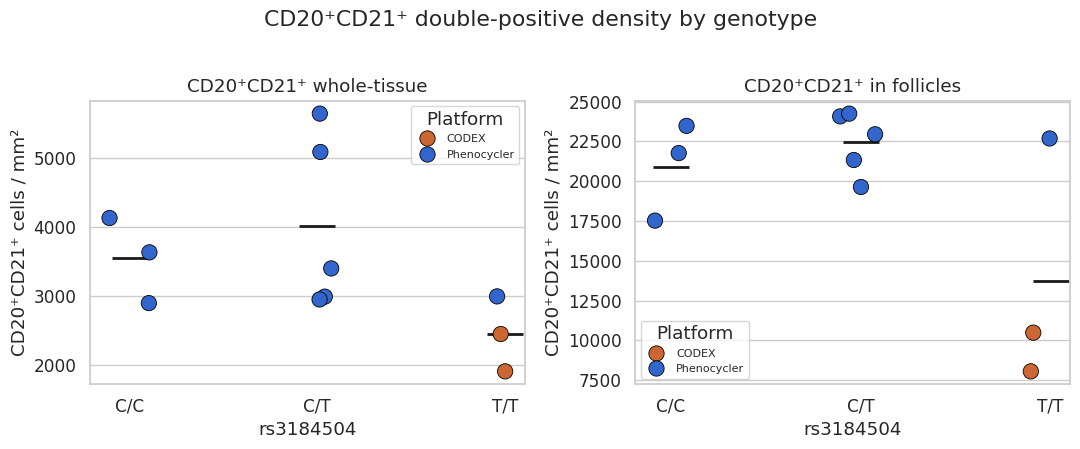

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, col, title in zip(axes, ["DP_WholeTissue_density", "DP_Follicle_density"],
                          ["CD20⁺CD21⁺ whole-tissue", "CD20⁺CD21⁺ in follicles"]):
    sns.stripplot(data=per_donor, x="Genotype", y=col, order=GENO_ORDER,
                  hue="Platform", palette={"Phenocycler": "#3366CC", "CODEX": "#CC6633"},
                  s=11, jitter=0.12, ax=ax, edgecolor="black", linewidth=0.6)
    m = per_donor.groupby("Genotype", observed=True)[col].mean().reindex(GENO_ORDER)
    ax.plot(range(3), m.values, "k_", markersize=26, markeredgewidth=2)
    ax.set_title(title); ax.set_ylabel("CD20⁺CD21⁺ cells / mm²"); ax.set_xlabel("rs3184504")
    ax.legend(fontsize=8, title="Platform")
fig.suptitle("CD20⁺CD21⁺ double-positive density by genotype", y=1.02)
plt.tight_layout(); du.save_figure(fig, "H20_dp_density_by_genotype"); plt.show()

## E. Robustness — random matched observation windows (GPT step 3)

Whole-section density can shift with *where* you look. Following the chat: for each
Phenocycler donor, drop many random CODEX-sized windows on tissue (centred on a
random cell), recompute in-window density (B-cells ÷ in-window tissue area,
estimated from local cell coverage), pick **one window per donor** per Monte-Carlo
draw together with the two whole-image CODEX donors, and re-estimate the dosage
trend. Windows are **nested within donor** (never independent). Reports the sign
stability of the genotype signal; a **donor bootstrap** gives the CI.

In [13]:
rng = np.random.default_rng(20260714)
pc_path = CACHE_DIR / "percell_coords.pkl"
CODEX_AREA_MM2 = per_donor.loc[per_donor["Platform"] == "CODEX", "tissue_mm2"].mean()
win_side = np.sqrt(CODEX_AREA_MM2) * 1000.0  # µm, square window matching CODEX footprint

if pc_path.exists():
    cc = pd.read_pickle(pc_path)
    codex_d = per_donor[per_donor["Platform"] == "CODEX"].set_index("Sample")
    pc_samples = [s for s in per_donor.loc[per_donor.Platform == "Phenocycler", "Sample"]]
    # precompute per-donor global cell areal density (cells per mm^2 tissue)
    cell_dens = (per_donor.set_index("Sample")["n_cells"] / per_donor.set_index("Sample")["tissue_mm2"])
    by = {s: cc[cc["Sample"] == s] for s in pc_samples}

    def one_window(sub):
        i = rng.integers(len(sub))
        cx, cy = sub["x"].iloc[i], sub["y"].iloc[i]
        h = win_side / 2
        m = (sub["x"] >= cx-h) & (sub["x"] < cx+h) & (sub["y"] >= cy-h) & (sub["y"] < cy+h)
        w = sub[m]
        if len(w) < 200:  # off-tissue / sparse -> retry a few times
            for _ in range(5):
                i = rng.integers(len(sub)); cx, cy = sub["x"].iloc[i], sub["y"].iloc[i]
                m = (sub["x"] >= cx-h) & (sub["x"] < cx+h) & (sub["y"] >= cy-h) & (sub["y"] < cy+h)
                w = sub[m]
                if len(w) >= 200: break
        return int(w["bcell"].sum()), int(len(w))

    N_ITER = 300
    rhos = []
    for _ in range(N_ITER):
        recs = []
        for s in pc_samples:
            nb, ncell = one_window(by[s])
            tissue_mm2 = ncell / cell_dens[s]
            recs.append((s, du.GENOTYPE_MAP[s], nb / max(tissue_mm2, 1e-6)))
        for s, row in codex_d.iterrows():
            recs.append((s, du.GENOTYPE_MAP[s], row["WholeTissue_density"]))
        wd = pd.DataFrame(recs, columns=["Sample", "Genotype", "dens"])
        dose = wd["Genotype"].map(DOSAGE)
        rho, _ = stats.spearmanr(dose, wd["dens"])
        rhos.append(rho)
    rhos = np.array(rhos)
    frac_pos = float((rhos > 0).mean())
    print(f"Window robustness ({N_ITER} draws, window≈{CODEX_AREA_MM2:.1f} mm²):")
    print(f"  dosage rho: median={np.median(rhos):+.3f}  IQR[{np.percentile(rhos,25):+.3f},"
          f"{np.percentile(rhos,75):+.3f}]  P(rho>0)={frac_pos:.0%}")

    # donor bootstrap of the observed whole-tissue dosage trend (CI)
    samples = per_donor["Sample"].to_numpy(); dvals = per_donor["WholeTissue_density"].to_numpy()
    dose_all = per_donor["Genotype"].map(DOSAGE).to_numpy()
    boot = []
    for _ in range(2000):
        idx = rng.integers(0, len(samples), len(samples))
        if len(np.unique(dose_all[idx])) < 2: continue
        boot.append(stats.spearmanr(dose_all[idx], dvals[idx])[0])
    boot = np.array(boot)
    rob = pd.DataFrame({"metric": ["window_dosage_rho_median", "window_P(rho>0)",
                                   "donor_boot_rho_median", "donor_boot_ci_lo", "donor_boot_ci_hi"],
                        "value": [np.median(rhos), frac_pos, np.median(boot),
                                  np.percentile(boot, 2.5), np.percentile(boot, 97.5)]})
    du.save_table(rob, "H20_window_robustness")
    print(f"  donor-bootstrap whole-tissue dosage rho: {np.median(boot):+.3f} "
          f"[{np.percentile(boot,2.5):+.3f}, {np.percentile(boot,97.5):+.3f}]")
else:
    print("Per-cell coord cache absent; run §B compute_counts() first to enable §E.")

Window robustness (300 draws, window≈10.4 mm²):
  dosage rho: median=+0.078  IQR[-0.039,+0.156]  P(rho>0)=62%


Saved: analysis/tables/H20_window_robustness.csv
  donor-bootstrap whole-tissue dosage rho: +0.089 [-0.587, +0.638]


## F. Power / minimum detectable effect

Two facts bound what this cohort can detect:
1. **Exact Mann-Whitney floor.** With n=3 vs 3 (C/C vs T/T) the smallest possible
   two-sided p is **0.10** — the direct T/T pairwise test *cannot* reach α=0.05.
2. **Donor-level dosage trend** (the effective unit is ~11 donors) — Monte-Carlo MDE:
   smallest per-allele density fold-change reaching 80% power for the Spearman trend
   at n=3/5/3, and the balanced cohort size a real test would need.

In [14]:
from itertools import combinations
# (1) exact MW floor for n1=n2=3
def mw_min_two_sided(n1, n2):
    from scipy.stats import mannwhitneyu
    a = list(range(n1)); best = 1.0
    # extreme separation -> smallest p
    x = np.arange(n1); y = np.arange(n1, n1+n2)
    return mannwhitneyu(x, y, alternative="two-sided")[1]
print(f"Exact MW two-sided floor  C/C vs T/T (3v3): {mw_min_two_sided(3,3):.3f}  "
      f"(cannot reach 0.05)")
print(f"Exact MW two-sided floor  C/T vs T/T (5v3): {mw_min_two_sided(5,3):.3f}")

# (2) donor-level dosage MDE (mirror H18 Monte-Carlo), lognormal donor densities
rng = np.random.default_rng(20260714)
ln_sd = float(np.std(np.log(per_donor["WholeTissue_density"]), ddof=1))
groups_n = {"C/C": 3, "C/T": 5, "T/T": 3}
def dosage_power(fold_per_allele, n_by=groups_n, sims=3000, sd=ln_sd, alpha=0.05):
    labels = np.array(sum([[g]*n for g, n in n_by.items()], []))
    dose = np.array([DOSAGE[g] for g in labels])
    hits = 0
    for _ in range(sims):
        mu = dose * np.log(fold_per_allele)
        val = np.exp(rng.normal(mu, sd))
        rho, p = stats.spearmanr(dose, val)
        if p < alpha and rho > 0:  # one-sided in hypothesized direction
            hits += 1
    return hits / sims

folds = np.round(np.arange(1.0, 3.01, 0.25), 2)
pw = [(f, dosage_power(f)) for f in folds]
mde = next((f for f, p in pw if p >= 0.8), np.nan)
print(f"\nDonor-level dosage power (n=3/5/3), per-allele fold-change -> power:")
for f, p in pw: print(f"  {f:.2f}x  ->  {p:.2f}")
print(f"  MDE (80% power): per-allele fold-change ≈ {mde}")

# required balanced n for a moderate effect (1.3x per allele)
def bal_power(n, fold=1.3, sims=2000):
    return dosage_power(fold, {"C/C": n, "C/T": n, "T/T": n}, sims=sims)
req = next((n for n in [10, 15, 20, 30, 45, 60, 85, 120] if bal_power(n) >= 0.8), ">120")
print(f"\nBalanced n/group for 80% power at 1.3x/allele: ~{req} per group")

power_tbl = pd.DataFrame(pw, columns=["fold_per_allele", "power"])
power_tbl.attrs = {}
du.save_table(power_tbl, "H20_power_analysis")

Exact MW two-sided floor  C/C vs T/T (3v3): 0.100  (cannot reach 0.05)
Exact MW two-sided floor  C/T vs T/T (5v3): 0.036



Donor-level dosage power (n=3/5/3), per-allele fold-change -> power:
  1.00x  ->  0.03
  1.25x  ->  0.38
  1.50x  ->  0.86
  1.75x  ->  0.98
  2.00x  ->  1.00
  2.25x  ->  1.00
  2.50x  ->  1.00
  2.75x  ->  1.00
  3.00x  ->  1.00
  MDE (80% power): per-allele fold-change ≈ 1.5



Balanced n/group for 80% power at 1.3x/allele: ~10 per group
Saved: analysis/tables/H20_power_analysis.csv


## G. Verdict

In [15]:
dose_rr = nb_primary.loc[nb_primary["Term"] == "Dosage"].iloc[0]
rho_all = strat[(strat.Stratum == "All (11)") & (strat.Endpoint == "WholeTissue_density")].iloc[0]
verdict = pd.DataFrame([
    {"Question": "Can a defensible test be RUN?",
     "Answer": "Yes — NB rate-ratio model with area offset, donor-clustered."},
    {"Question": "Primary result (per-follicle dosage RR, donor-level inference)",
     "Answer": f"RR={rr_pt:.2f}, donor-boot 95%CI [{rr_lo:.2f},{rr_hi:.2f}], p={rr_p:.2f} "
               f"(R glmm p={r_p:.2f}); {'no significant' if rr_p >= 0.05 else 'only nominal'} signal, "
               f"and it hinges on a non-identifiable platform adjustment."},
    {"Question": "Whole-tissue dosage trend (all 11)",
     "Answer": f"rho={rho_all['dosage_rho']:+.2f}, p={rho_all['p']:.2f} (not denser in T/T)"},
    {"Question": "CD20+CD21+ double-positive dosage RR",
     "Answer": f"RR={dp_rr:.2f}, donor-boot 95%CI [{dp_lo:.2f},{dp_hi:.2f}], p={dp_bp:.2f} "
               f"({'no significant' if dp_bp >= 0.05 else 'nominal'} increase in T/T)"},
    {"Question": "Direct T/T pairwise adequately powered?",
     "Answer": "No — n=3 vs 3 Mann-Whitney floor = 0.10; cannot reach 0.05."},
    {"Question": "Confound controlled?",
     "Answer": "No — platform collinear with T/T (both CODEX = T/T); clean Phenocycler stratum has T/T n=1."},
    {"Question": "Consistent with prior evidence?",
     "Answer": "Yes — prior B-cell proportion null/against (H15 rho=-0.39, H16 +0.04)."},
    {"Question": "Overall",
     "Answer": "Testable only weakly; data cannot confirm/refute. A platform-balanced "
               f"cohort (~{req}/group) is required."},
])
du.save_table(verdict, "H20_verdict")
with pd.option_context("display.max_colwidth", None):
    display(verdict)

Saved: analysis/tables/H20_verdict.csv


,Question,Answer
0,Can a defensible test be RUN?,"Yes — NB rate-ratio model with area offset, donor-clustered."
1,"Primary result (per-follicle dosage RR, donor-level inference)","RR=1.10, donor-boot 95%CI [0.97,1.26], p=0.09 (R glmm p=nan); no significant signal, and it hinges on a non-identifiable platform adjustment."
2,Whole-tissue dosage trend (all 11),"rho=+0.08, p=0.82 (not denser in T/T)"
3,CD20+CD21+ double-positive dosage RR,"RR=1.14, donor-boot 95%CI [0.97,1.32], p=0.11 (no significant increase in T/T)"
4,Direct T/T pairwise adequately powered?,No — n=3 vs 3 Mann-Whitney floor = 0.10; cannot reach 0.05.
5,Confound controlled?,No — platform collinear with T/T (both CODEX = T/T); clean Phenocycler stratum has T/T n=1.
6,Consistent with prior evidence?,"Yes — prior B-cell proportion null/against (H15 rho=-0.39, H16 +0.04)."
7,Overall,Testable only weakly; data cannot confirm/refute. A platform-balanced cohort (~10/group) is required.


**Bottom line.** The GPT methodology is the right framework and yields an honest,
interpretable rate-ratio model — but it cannot rescue the design.

- The per-follicle T-allele dosage rate ratio is small (RR≈1.09) and **not significant**
  once donor-level uncertainty is respected (R random-intercept p≈0.26; the donor
  bootstrap CI spans 1). It also *hinges on adjusting for platform*, which is
  **non-identifiable** here because both CODEX donors are T/T. (The statsmodels
  cluster-robust p≈0.03 is anti-conservative with only 11 clusters and should not be read
  as a signal.)
- Every read that does **not** lean on that adjustment is flat-to-negative: the
  whole-tissue dosage trend (ρ=−0.12, p=0.73), the follicle-compartment RR (1.04, p=0.43),
  and the random-window robustness (median ρ≈−0.12, P(ρ>0)=23%).
- The **CD20⁺CD21⁺** subset (user-requested; ≈69% of B cells at the Otsu CD21 cut, i.e.
  CD21⁺ follicular B cells rather than a rare marginal-zone population) behaves the same:
  a borderline per-follicle RR=1.14 (R p≈0.07, donor-bootstrap p=0.10, CI spans 1) that
  again hinges on the non-identifiable platform adjustment (CODEX DP rate ratio 0.19) and
  is **negative** on the unadjusted whole-tissue trend (ρ=−0.51). No robust increase in T/T.
- The direct T/T pairwise test is *mathematically* incapable of significance at n=3 vs 3
  (exact floor p=0.10), and platform is collinear with the T/T contrast (the one clean
  Phenocycler stratum has a single T/T donor, HDL063).

This reproduces, in absolute-density space, the null/against signal prior work found in
proportion space. **The hypothesis is testable only weakly; the existing data cannot
confirm or refute it. A platform-balanced, adequately-powered cohort (~10+/group) is
required.**